# Activity: The Suspicious Transactions Case

**Unit 2: Advanced Visualization & Storytelling (UE24CS342AA9)**
**Format:** Scenario-based, hands-on coding activity
**Estimated time:** 20–30 minutes
**You will need:** what you learned about node-link diagrams, force-directed layout, network tasks, and adjacency matrices.

---

## The Scenario

You are a **junior data analyst** at a bank's fraud-investigation unit. The fraud-monitoring system has flagged an unusual cluster of accounts and handed you a network dataset:

- **Nodes** = bank accounts, each with attributes: `flagged` (already suspected of fraud), `account_type` (`personal`/`business`), `device_id` (the device most commonly used to log in).
- **Edges** = a transaction occurred between two accounts, with attribute `amount` (total amount transferred, in ₹ thousands).

Your manager wants a short brief answering: **"Is there an organized fraud ring here, or is this just noise? Which accounts should we investigate first, and how should we present this network to the compliance team?"**

You'll work through the same steps a real analyst would: explore the data, run topology and combination queries, visualize it as a node-link diagram, then as an adjacency matrix — and decide which representation actually helps you make the call.

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own words 

## Part 0 — Setup (given)

Run this cell as-is. It builds the account network you'll be investigating. Don't change it — but do look at it, since Part 1 asks you questions about exactly what it built.

In [1]:
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
np.random.seed(7)

G = nx.Graph()

# 15 accounts across two "legitimate-looking" clusters and one suspicious ring
accounts = {
    # Cluster A: ordinary personal accounts
    "A1": {"flagged": False, "account_type": "personal", "device_id": "dev-101"},
    "A2": {"flagged": False, "account_type": "personal", "device_id": "dev-102"},
    "A3": {"flagged": False, "account_type": "personal", "device_id": "dev-103"},
    "A4": {"flagged": False, "account_type": "personal", "device_id": "dev-104"},
    # Cluster B: ordinary business accounts
    "B1": {"flagged": False, "account_type": "business", "device_id": "dev-201"},
    "B2": {"flagged": False, "account_type": "business", "device_id": "dev-202"},
    "B3": {"flagged": False, "account_type": "business", "device_id": "dev-203"},
    "B4": {"flagged": False, "account_type": "business", "device_id": "dev-204"},
    # Suspicious ring: several accounts sharing the SAME device_id (red flag!)
    "S1": {"flagged": True,  "account_type": "personal", "device_id": "dev-999"},
    "S2": {"flagged": False, "account_type": "personal", "device_id": "dev-999"},
    "S3": {"flagged": False, "account_type": "personal", "device_id": "dev-999"},
    "S4": {"flagged": False, "account_type": "business", "device_id": "dev-999"},
    "S5": {"flagged": False, "account_type": "personal", "device_id": "dev-777"},
    # A hub account that many others route money through
    "HUB": {"flagged": False, "account_type": "business", "device_id": "dev-301"},
    # A quiet, unconnected-looking account
    "X1": {"flagged": False, "account_type": "personal", "device_id": "dev-401"},
}
for acc, attrs in accounts.items():
    G.add_node(acc, **attrs)

transactions = [
    ("A1", "A2", 12), ("A2", "A3", 8), ("A3", "A4", 15), ("A1", "A4", 6),
    ("B1", "B2", 40), ("B2", "B3", 55), ("B3", "B4", 30), ("B1", "B4", 22),
    ("S1", "S2", 5), ("S1", "S3", 6), ("S1", "S4", 4), ("S2", "S3", 7), ("S3", "S4", 5), ("S1", "S5", 3),
    ("HUB", "A2", 18), ("HUB", "B2", 60), ("HUB", "S2", 25), ("HUB", "A4", 9), ("HUB", "B4", 33), ("HUB", "S4", 20),
]
for u, v, amt in transactions:
    G.add_edge(u, v, amount=amt)

print(f"Network built: {G.number_of_nodes()} accounts, {G.number_of_edges()} transactions.")

Network built: 15 accounts, 20 transactions.


## Part 1 — Get to Know the Data 

Before running any analysis, an analyst always looks at what they've been handed.

**TODO:**
1. Print the total number of accounts and transactions.
2. Print the list of accounts that are already `flagged`.
3. Print the full attribute dictionary for account `"HUB"`.

In [2]:
print("Accounts:", G.number_of_nodes())
print("Transactions:", G.number_of_edges())

flagged = [node for node, attrs in G.nodes(data=True) if attrs["flagged"]]
print("Flagged accounts:", flagged)

print("HUB attributes:", G.nodes["HUB"])


Accounts: 15
Transactions: 20
Flagged accounts: ['S1']
HUB attributes: {'flagged': False, 'account_type': 'business', 'device_id': 'dev-301'}


**Reflection 1:** Only one account (`S1`) came pre-flagged by the system. Based on nothing but the raw data you just printed, do you already suspect any *other* accounts might be worth a closer look — and why?

_(Write your answer here.)_

S2, S3, and S4 deserve closer attention because they share S1's device_id dev-999, and S1 is already flagged. HUB should also be monitored because it connects many clusters, although that alone is not proof of fraud.

## Part 2 — Topology Tasks: Paths, Neighbours, Centrality 
Recall from lecture: **topology-based tasks** include finding paths, finding neighbours, and comparing centrality/importance measures.

**TODO:**
1. Find the shortest path between `"S1"` (the flagged account) and `"B3"`. Does money reach a "legitimate-looking" cluster?
2. List the direct neighbours (transaction partners) of `"HUB"`.
3. Compute **degree centrality** for every account and print the top 3 accounts by centrality.

In [3]:
shortest = nx.shortest_path(G, source="S1", target="B3")
print("Shortest S1-to-B3 path:", shortest)

print("HUB neighbours:", list(G.neighbors("HUB")))

centrality = nx.degree_centrality(G)
top3 = sorted(centrality.items(), key=lambda item: item[1], reverse=True)[:3]
print("Top 3 degree-centrality accounts:", top3)


Shortest S1-to-B3 path: ['S1', 'S2', 'HUB', 'B2', 'B3']
HUB neighbours: ['A2', 'B2', 'S2', 'A4', 'B4', 'S4']
Top 3 degree-centrality accounts: [('HUB', 0.42857142857142855), ('S1', 0.2857142857142857), ('A2', 0.21428571428571427)]


** Reflection 2:** In a fraud-investigation context, what could a very high centrality score on an account like `HUB` mean? Give one legitimate explanation and one suspicious explanation.

_(Write your answer here.)_

Legitimately, HUB could be a payment processor or central business account. Suspiciously, unusually high centrality could indicate a routing account used to pass money through several accounts or conceal the origin and destination of transfers.

## Part 3 — Combination Task: Topology + Attributes 

This is the exact kind of task the lecture used as its running example (*"find friends of friends who like cats"*): mix a **topology** step (traverse the graph) with an **attribute** step (filter by a property).

**Your task:** Investigators suspect that accounts sharing the same `device_id` as a flagged account are part of the same ring, *even if they aren't directly connected by a transaction*.

**TODO:** Write a function `same_device_within_2_hops(graph, start_account)` that:
1. Finds all accounts within 2 hops of `start_account` (topology step — use `nx.single_source_shortest_path_length(graph, start_account, cutoff=2)`, then drop `start_account` itself).
2. Filters that set down to only accounts whose `device_id` attribute matches `start_account`'s `device_id` (attribute step).
3. Returns that filtered list.

Then call it with `start_account="S1"`.

In [4]:
def same_device_within_2_hops(graph, start_account):
    within_two = nx.single_source_shortest_path_length(graph, start_account, cutoff=2)
    start_device = graph.nodes[start_account]["device_id"]
    return [
        node for node in within_two
        if node != start_account and graph.nodes[node]["device_id"] == start_device
    ]

suspects = same_device_within_2_hops(G, "S1")
print("Accounts sharing S1's device within 2 hops:", suspects)


Accounts sharing S1's device within 2 hops: ['S2', 'S3', 'S4']


**Reflection 3:** Compare your `suspects` list to the neighbours you printed for `HUB` in Part 2. Is `HUB` itself flagged by your function? Should it be considered part of the ring — why or why not?

The function should return S2, S3, and S4 because they share S1's device ID and are within two hops. HUB is not returned because its device ID differs; it may be operationally important as a connector, but that does not make it part of the shared-device ring.

## Part 4 — Visualize as a Node-Link Diagram 

Time to build a visual an investigator (or your manager) could actually look at.

**TODO:** Draw the network as a node-link diagram where:
- **Node color** encodes `flagged` status (e.g. red if flagged, else a neutral color)
- **Node size** encodes degree centrality (bigger = more connected)
- **Edge width** encodes transaction `amount`

Use `nx.spring_layout` for positions. Add a legend or title explaining the encoding.

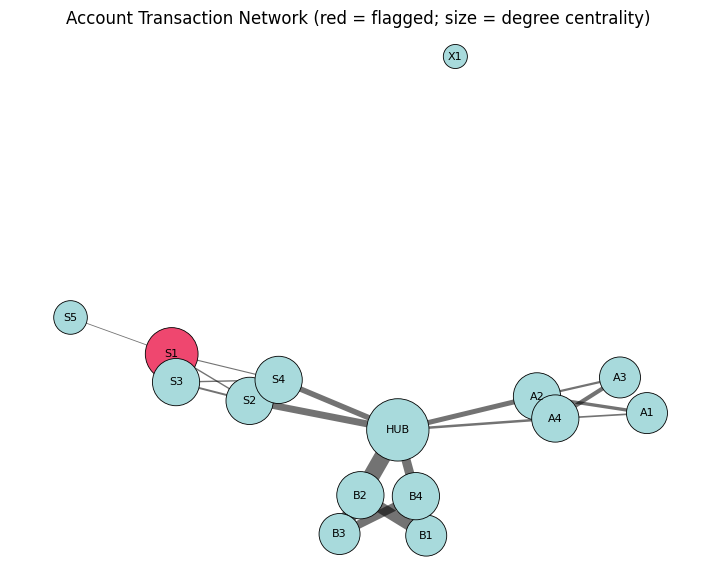

In [5]:
pos = nx.spring_layout(G, seed=3)

node_colors = ["#ef476f" if G.nodes[n]["flagged"] else "#a8dadc" for n in G.nodes()]
centrality = nx.degree_centrality(G)
node_sizes = [300 + 4000 * centrality[n] for n in G.nodes()]
edge_widths = [G[u][v]["amount"] / 5 for u, v in G.edges()]

plt.figure(figsize=(9, 7))
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_sizes, edgecolors="black", linewidths=0.6)
nx.draw_networkx_edges(G, pos, width=edge_widths, alpha=0.55)
nx.draw_networkx_labels(G, pos, font_size=8)
plt.title("Account Transaction Network (red = flagged; size = degree centrality)")
plt.axis("off")
plt.show()


**Reflection 4:** Look at your finished plot. Can you visually spot the suspicious cluster without having run any code in Parts 2–3? Is the node-link diagram already cluttered at just 15 nodes — what do you predict would happen at 500 accounts?

_(Write your answer here.)_

The red S1 node and the concentrated S1-S5 cluster are visible, but the 15-node diagram is already somewhat crowded. At 500 accounts, a force-directed layout would likely become a hairball, obscuring community structure and making hub or clique patterns hard to read.

## Part 5 — Build and Read an Adjacency Matrix 

**TODO:**
1. Compute the adjacency matrix for `G` using the **default** node order (`list(G.nodes())`).
2. Detect communities with `nx.algorithms.community.greedy_modularity_communities(G)`, and build a **reordered** node list where nodes are grouped by community.
3. Plot both matrices side by side (`plt.imshow`, `cmap="Reds"`).
4. Identify which lecture "pattern" (diagonal block / off-diagonal block / band / star-hub / bipartite / clique) the reordered matrix shows for the suspicious ring, and for `HUB`.

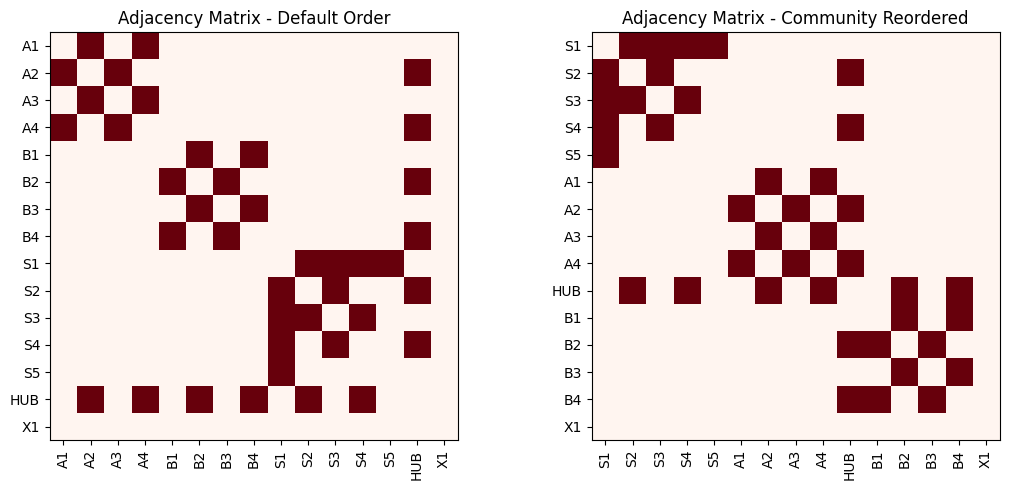

In [6]:
nodes_default = list(G.nodes())
adj_default = nx.to_numpy_array(G, nodelist=nodes_default)

communities = list(nx.algorithms.community.greedy_modularity_communities(G))
nodes_reordered = [node for community in communities for node in nodes_default if node in community]
adj_reordered = nx.to_numpy_array(G, nodelist=nodes_reordered)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(adj_default, cmap="Reds")
axes[0].set_title("Adjacency Matrix - Default Order")
axes[0].set_xticks(range(len(nodes_default))); axes[0].set_xticklabels(nodes_default, rotation=90)
axes[0].set_yticks(range(len(nodes_default))); axes[0].set_yticklabels(nodes_default)

axes[1].imshow(adj_reordered, cmap="Reds")
axes[1].set_title("Adjacency Matrix - Community Reordered")
axes[1].set_xticks(range(len(nodes_reordered))); axes[1].set_xticklabels(nodes_reordered, rotation=90)
axes[1].set_yticks(range(len(nodes_reordered))); axes[1].set_yticklabels(nodes_reordered)
plt.tight_layout()
plt.show()


**Reflection 5:** Which pattern from the lecture (diagonal block, off-diagonal block, band, star/hub, bipartite, clique) best describes:
- (a) the S1–S2–S3–S4 ring in your reordered matrix?
- (b) the `HUB` account's row/column?

_(Write your answer here.)_

The S1-S2-S3-S4 ring is most like a dense diagonal block or clique within its community, especially after community reordering. HUB appears as a star/hub pattern: its row and column contain contacts across several otherwise distinct blocks.

## Part 6 — The Decision (No Code)

Your manager only has time to look at **one** visualization before the compliance meeting, and the real dataset has **500 accounts**, not 15.

**Reflection 6 (final):** Write a 3–5 sentence recommendation to your manager. Your answer should:
- State whether you'd show them the node-link diagram, the adjacency matrix, or a NodeTrix-style hybrid, **at 500-account scale**.
- Justify it using at least one specific idea from the lecture (e.g. the "hairball effect," matrix scalability to ~1k nodes/1M edges, or NodeTrix combining both).
- Name which accounts you'd tell the compliance team to investigate first, and why.

_(Write your final recommendation here.)_

For 500 accounts, I would use an adjacency matrix or a NodeTrix-style hybrid rather than a plain node-link diagram, because node-link layouts become hairballs while matrices scale to roughly thousands of nodes and preserve block structure. I would investigate S1, S2, S3, S4, and S5 first because S2-S4 share S1's device_id dev-999 and S5 is within the two-hop ring search. I would place HUB second for transaction-hub review, since its connections span all clusters but shared-device evidence alone does not implicate it.